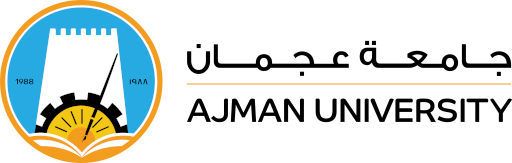

<p>
College: Engineering and Information Technology<br>
Department: Information Technology<br>
Program: Data Analytics<br>
Academic Semester: Spring 2025-2026<br>
Course: DAT405 Machine Learning Lab<br>
Course Instructor: Prof. Mahmoud AlShboul<br>
</p></center>

Student ID: _______________<br>
Student Name: _________________

# **Lab 1: Feature Extraction, Feature Selection, Dimensionality Reduction Techniques**

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from skimage.io import imread, imshow
from keras.datasets import mnist

In [4]:
(train_X, train_y), (test_X, test_y) = mnist.load_data()
print('X_train: ' + str(train_X.shape))
print('Y_train: ' + str(train_y.shape))
print('X_test:  ' + str(test_X.shape))
print('Y_test:  ' + str(test_y.shape))

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
X_train: (60000, 28, 28)
Y_train: (60000,)
X_test:  (10000, 28, 28)
Y_test:  (10000,)


In [5]:
#Checking the image shape
train_X[0].shape

(28, 28)

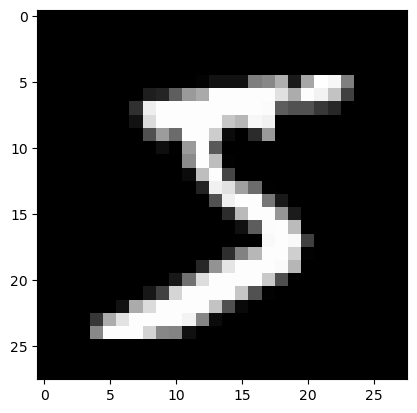

In [6]:
plt.imshow(train_X[0], cmap=plt.get_cmap('gray'))

## Image Feature Extraction
### Method 1: Grayscale Pixel Values as Features

The simplest way to create features from an image is to use the raw pixel values as separate features.

/tmp/ipykernel_17821/3388434941.py:3: FutureWarning: `imshow` is deprecated since version 0.25 and will be removed in version 0.27. Please use `matplotlib`, `napari`, etc. to visualize images.
  image.shape, imshow(image)


((1500, 1000), <matplotlib.image.AxesImage at 0x7dff9098ae90>)

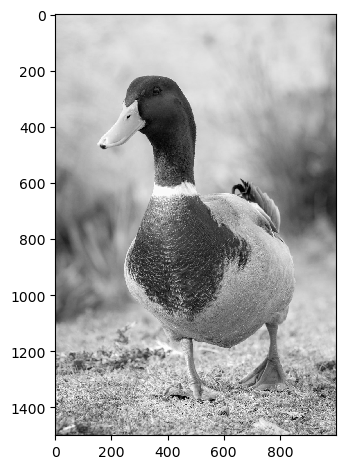

In [9]:
#let's take an example
image = imread('duck.jpeg', as_gray=True)
image.shape, imshow(image)
# 28x28 = 784 pixels

#generating a feature vector


In [6]:
#generating a feature vector
features = np.reshape(image, (1500*1000))

features.shape, features

((1500000,),
 array([0.85679882, 0.85679882, 0.85679882, ..., 0.43467843, 0.5615149 ,
        0.64691843]))

### Method 2: Mean Pixel Value of Channels
Instead of using the pixel values from the three channels separately, we can generate a new matrix that has the mean value of the pixels from all three channels

In [10]:
image = imread('duck.jpeg')
image.shape

(1500, 1000, 3)

In [8]:
image = imread('duck.jpeg')
feature_matrix = np.zeros((1500,1000))
feature_matrix.shape

(1500, 1000)

In [9]:
for i in range(0,image.shape[0]):
    for j in range(0,image.shape[1]):
        feature_matrix[i][j] = ((int(image[i,j,0]) + int(image[i,j,1]) + int(image[i,j,2]))/3)

In [10]:
features = np.reshape(feature_matrix, (1500*1000))
features.shape

(1500000,)

### Method 3: Extracting Edge Features
Edges are sharp changes in color in an image.
Some of the edge filters that are used.   
1. Prewitt kernel
2. Sobel kernel
3. Scharr kernel


https://scikit-image.org/docs/stable/api/skimage.filters.html


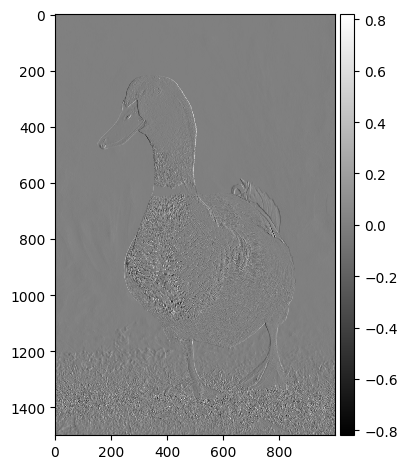

In [11]:
import numpy as np
from skimage.io import imread, imshow
from skimage.filters import scharr_v,prewitt_v,sobel_v
import matplotlib.pyplot as plt


#reading the image
image = imread('duck.jpeg',as_gray=True)
#calculating vertical edges using prewitt kernel
edges_prewitt_vertical = prewitt_v(image)

imshow(edges_prewitt_vertical, cmap='gray')

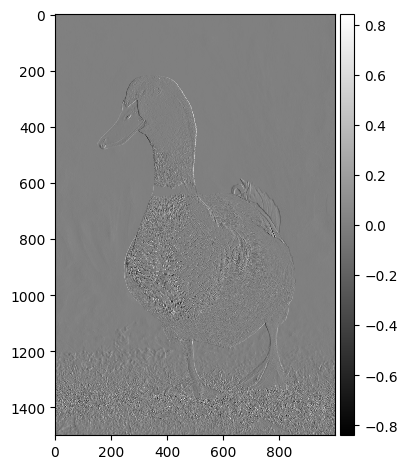

In [12]:
edges_scharr_vertical = scharr_v(image)

imshow(edges_scharr_vertical, cmap='gray')

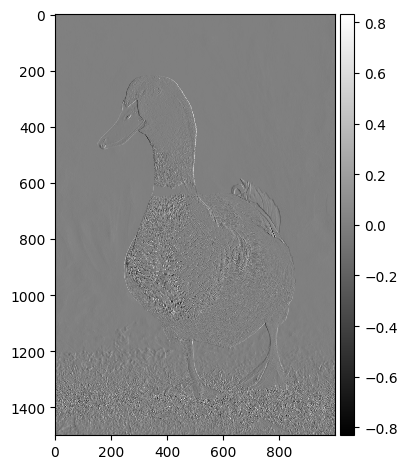

In [13]:
edges_sobel_vertical = sobel_v(image)

imshow(edges_sobel_vertical, cmap='gray')

### Feature Selection  
Feature selection is the process of **selecting a subset of relevant features** for use in machine learning model building.

We perform feature selection for the following advantages:
1. Simple models are easier to interpret.
2. Shorter ML training time.
3. Enhanced generalization by reducing overfitting.
4. Reduced risk of data errors during model use.

Feature selection methods:  
**1. Filter Methods**  
**2. Wrapper Methods**

#### Filter Methods
1. It relies in the characteristics of the feature.
2. It doesn't use any machine learning algorithms.
3. Model agnostic.
4. Tends to be less computationally expensive.
5. Usually gives lower prediction performance than a wrapper method.
6. Very well suited for a quick screen and removal of irrelevant features.


**Filter Method Techniques:**
1. Basic - constant, quasi-constant, and duplicated features
2. Correlation
3. Statistical


### Filter Technique - Basic

In [14]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import VarianceThreshold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

In [15]:
#data = pd.read_csv("/content/creditcard_sample.csv")
data = pd.read_csv("https://raw.githubusercontent.com/codingnest/FeatureSelection/master/dataset/santander.csv")
data.shape

(76020, 371)

In [16]:
#Splitting the dataframe vertically to x (input) and y (output)
x = data.iloc[:,:-1]
y = data.iloc[:,-1]

In [17]:
#Splitting the dataset horizontally to training and testing sets
X_train,X_test,y_train,y_test = train_test_split(x,y,test_size=0.3,random_state=0)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(53214, 370)
(22806, 370)
(53214,)
(22806,)


In [18]:
X_train_original = X_train.copy()
X_test_original = X_test.copy()

In [19]:
#In this step, we are creating a function to evalaute the performance of the different techniques in machine learning algorithms
def run_randomForests(X_train, X_test, y_train, y_test):
    rf = RandomForestClassifier(n_estimators=200, random_state=39, max_depth=4)
    rf.fit(X_train, y_train)
    print('Train Set')
    pred = rf.predict_proba(X_train)
    print("Train Results roc-auc {}".format(roc_auc_score(y_train, pred[:,1])))
    print('Test Set')
    pred= rf.predict_proba(X_test)
    print("Test Results roc-auc {}".format(roc_auc_score(y_test, pred[:,1])))

Constant features - numerical  
**VarianceThreshold** from sklearn, it removes all features whose variance doesn't meet some threshold. It also removes all zero-variance features

In [20]:
VThreshold = VarianceThreshold(threshold=0)
VThreshold.fit(X_train)

VarianceThreshold(threshold=0)

In [21]:
#get_support() is a boolean vector that indicates which features are retained
sum(VThreshold.get_support())

332

In [22]:
#Showing the list of features that got removed from the dataframe
print([x for x in X_train.columns if x not in X_train.columns[VThreshold.get_support()]])

['ind_var2_0', 'ind_var2', 'ind_var27_0', 'ind_var28_0', 'ind_var28', 'ind_var27', 'ind_var41', 'ind_var46_0', 'ind_var46', 'num_var27_0', 'num_var28_0', 'num_var28', 'num_var27', 'num_var41', 'num_var46_0', 'num_var46', 'saldo_var28', 'saldo_var27', 'saldo_var41', 'saldo_var46', 'delta_imp_reemb_var33_1y3', 'delta_num_reemb_var33_1y3', 'imp_amort_var18_hace3', 'imp_amort_var34_hace3', 'imp_reemb_var13_hace3', 'imp_reemb_var33_hace3', 'imp_reemb_var33_ult1', 'imp_trasp_var17_out_hace3', 'imp_trasp_var33_out_hace3', 'num_var2_0_ult1', 'num_var2_ult1', 'num_reemb_var13_hace3', 'num_reemb_var33_hace3', 'num_reemb_var33_ult1', 'num_trasp_var17_out_hace3', 'num_trasp_var33_out_hace3', 'saldo_var2_ult1', 'saldo_medio_var13_medio_hace3']


In [23]:
features_to_keep = X_train.columns[VThreshold.get_support()]

In [24]:
X_train = VThreshold.transform(X_train)
X_test = VThreshold.transform(X_test)

print(X_train.shape, X_test.shape)

(53214, 332) (22806, 332)


In [25]:
#Evaluating the performance
run_randomForests(X_train_original, X_test_original, y_train, y_test)

Train Set
Train Results roc-auc 0.8011567441366869
Test Set
Test Results roc-auc 0.7903898679453263


In [26]:
run_randomForests(X_train, X_test, y_train, y_test)

Train Set
Train Results roc-auc 0.8027070226730222
Test Set
Test Results roc-auc 0.7920500469581926


Quasi-constant features

In [27]:
X_train = pd.DataFrame(X_train)
X_train.columns = features_to_keep
X_test = pd.DataFrame(X_test)
X_test.columns = features_to_keep

In [28]:
X_train

,ID,var3,var15,imp_ent_var16_ult1,imp_op_var39_comer_ult1,imp_op_var39_comer_ult3,imp_op_var40_comer_ult1,imp_op_var40_comer_ult3,imp_op_var40_efect_ult1,imp_op_var40_efect_ult3,...,saldo_medio_var29_ult3,saldo_medio_var33_hace2,saldo_medio_var33_hace3,saldo_medio_var33_ult1,saldo_medio_var33_ult3,saldo_medio_var44_hace2,saldo_medio_var44_hace3,saldo_medio_var44_ult1,saldo_medio_var44_ult3,var38
0,15083.0,2.0,23.0,0.0,0.00,0.00,0.00,0.00,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,117310.979016
1,103706.0,2.0,48.0,0.0,0.00,0.00,0.00,0.00,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,451931.220000
2,93351.0,2.0,40.0,0.0,0.00,0.00,0.00,0.00,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,41225.670000
3,92424.0,2.0,83.0,0.0,0.00,0.00,0.00,0.00,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,117310.979016
4,40437.0,2.0,79.0,0.0,535.41,535.41,0.00,0.00,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,153477.690000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
53209,42533.0,53.0,46.0,0.0,1770.48,2669.46,451.74,808.77,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,124242.570000
53210,91801.0,2.0,29.0,0.0,0.00,0.00,0.00,0.00,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,34968.270000
53211,85345.0,9.0,23.0,0.0,0.00,0.00,0.00,0.00,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,69090.870000
53212,87270.0,2.0,30.0,60.0,72.48,95.64,0.00,0.00,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,66354.510000


In [29]:
QuasiVT = VarianceThreshold(threshold=0.01)
QuasiVT.fit(X_train)

VarianceThreshold(threshold=0.01)

In [30]:
sum(QuasiVT.get_support())

268

In [31]:
print([x for x in X_train.columns if x not in X_train.columns[QuasiVT.get_support()]])

['ind_var1', 'ind_var6_0', 'ind_var6', 'ind_var13_largo', 'ind_var13_medio_0', 'ind_var13_medio', 'ind_var14', 'ind_var17_0', 'ind_var17', 'ind_var18_0', 'ind_var18', 'ind_var19', 'ind_var20_0', 'ind_var20', 'ind_var29_0', 'ind_var29', 'ind_var30_0', 'ind_var31_0', 'ind_var31', 'ind_var32_cte', 'ind_var32_0', 'ind_var32', 'ind_var33_0', 'ind_var33', 'ind_var34_0', 'ind_var34', 'ind_var40', 'ind_var39', 'ind_var44_0', 'ind_var44', 'num_var6_0', 'num_var6', 'num_var13_medio_0', 'num_var13_medio', 'num_var18_0', 'num_var18', 'num_var29_0', 'num_var29', 'num_var33', 'num_var34_0', 'num_var34', 'delta_imp_aport_var33_1y3', 'delta_num_aport_var33_1y3', 'ind_var7_emit_ult1', 'ind_var7_recib_ult1', 'num_aport_var33_hace3', 'num_aport_var33_ult1', 'num_var7_emit_ult1', 'num_compra_var44_hace3', 'num_meses_var13_medio_ult3', 'num_meses_var17_ult3', 'num_meses_var29_ult3', 'num_meses_var33_ult3', 'num_meses_var44_ult3', 'num_reemb_var13_ult1', 'num_reemb_var17_hace3', 'num_reemb_var17_ult1', 'num

In [32]:
features_to_keep = X_train.columns[QuasiVT.get_support()]

In [33]:
X_train = QuasiVT.transform(X_train)
X_test = QuasiVT.transform(X_test)
print(X_train.shape, X_test.shape)

(53214, 268) (22806, 268)


In [34]:
#Original data
run_randomForests(X_train_original, X_test_original, y_train, y_test)
# Quasi-Constant values Removal
run_randomForests(X_train, X_test, y_train, y_test)

Train Set
Train Results roc-auc 0.8011567441366869
Test Set
Test Results roc-auc 0.7903898679453263
Train Set
Train Results roc-auc 0.8003515381528266
Test Set
Test Results roc-auc 0.7892766099423427


### Filter Technique - Correlation  
1. Correlation is a measure of the linear relationship of 2 or more variables.
2. Through correlation, we can predict one varialbe from the other.
3. Variables should be correlated with the target but uncorrelated with themselves.
4. If 2 features are highly correlated, then the second one will add little information over the previous one, so removing it helps reduce the dimensionality.

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [36]:
X_train = pd.DataFrame(X_train)
X_train.columns = features_to_keep
X_test = pd.DataFrame(X_test)
X_test.columns = features_to_keep

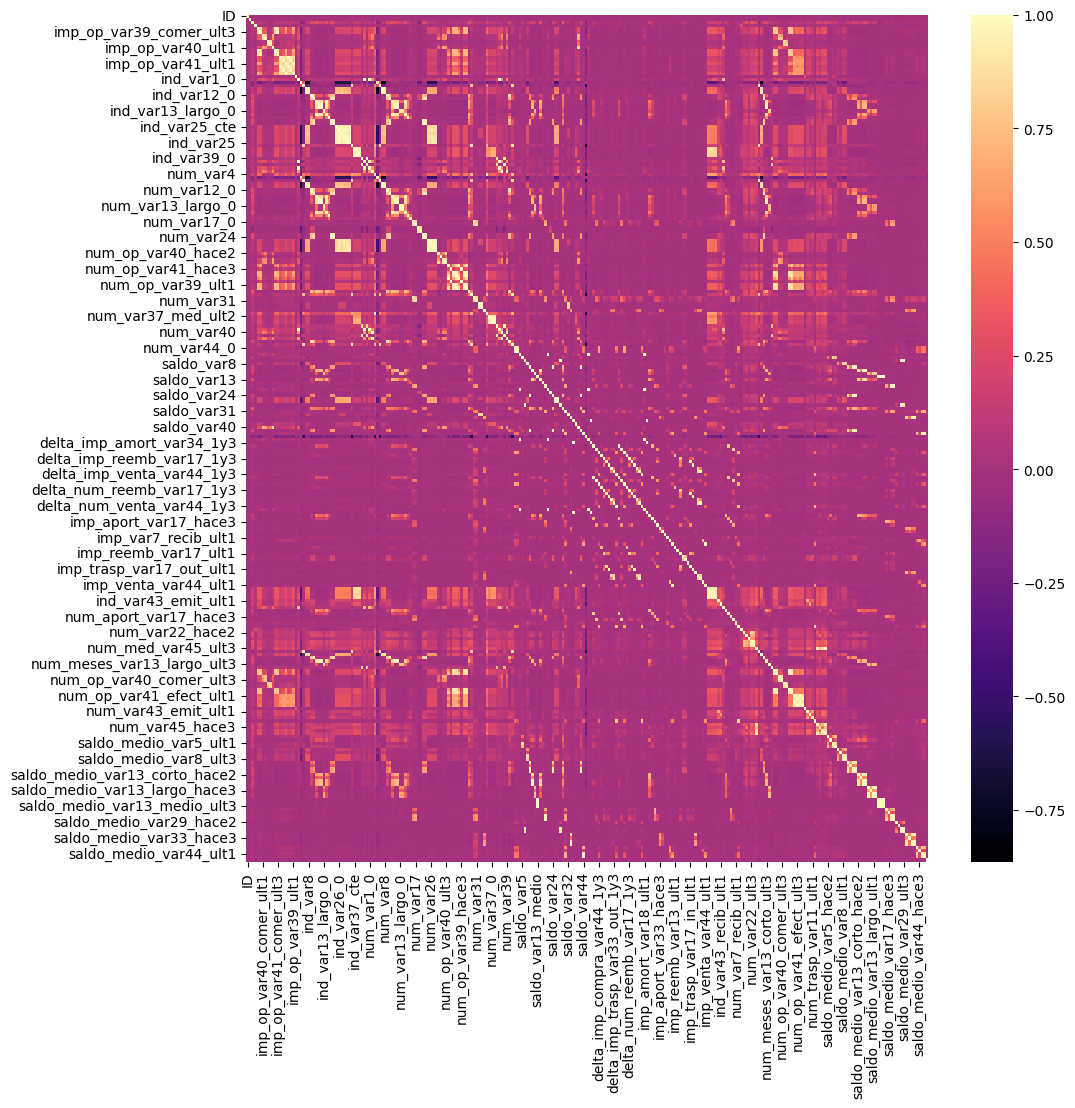

In [37]:
corr_mat = X_train.corr()
fig, ax = plt.subplots()
fig.set_size_inches(11,11)
sns.heatmap(corr_mat, cmap='magma');

In [38]:
def correlation(dataset, threshold):
    col_corr = set()
    corr_matrix = dataset.corr()
    for i in range(0, len(corr_matrix.columns)):
        for j in range(i):
            if abs(corr_matrix.iloc[i,j]) > threshold:
                colname = corr_matrix.columns[i]
                col_corr.add(colname)
    return col_corr

In [39]:
corr_features = correlation(X_train,0.8)
len(set(corr_features))

149

In [40]:
X_train.drop(labels=set(corr_features), axis=1, inplace=True)
X_test.drop(labels=set(corr_features), axis=1, inplace=True)

print(X_train.shape, X_test.shape)

(53214, 119) (22806, 119)


In [41]:
#Original data
run_randomForests(X_train_original, X_test_original, y_train, y_test)
#High Correlation values Removal
run_randomForests(X_train, X_test, y_train, y_test)

Train Set
Train Results roc-auc 0.8011567441366869
Test Set
Test Results roc-auc 0.7903898679453263
Train Set
Train Results roc-auc 0.8080169064904122
Test Set
Test Results roc-auc 0.7951632012093584


### Filter Technique - Statistical

Information Gain - Mutual Information: It measures how much information the presence/absence of a feature contributes to making the correct prediction on Y. Mutual Information is the same as the entropy of X and as the entropy of Y.

In [42]:
from sklearn.feature_selection import mutual_info_classif, mutual_info_regression
from sklearn.feature_selection import SelectKBest, SelectPercentile

In [43]:
mi = mutual_info_classif(X_train, y_train)
mi = pd.Series(mi)
mi.index = X_train.columns
mi.sort_values(ascending=False)

ind_var5                      0.018409
num_var4                      0.015232
saldo_var30                   0.014168
var15                         0.013280
ind_var5_0                    0.011879
                                ...   
var21                         0.000000
delta_imp_compra_var44_1y3    0.000000
num_var7_recib_ult1           0.000000
num_var22_hace2               0.000000
saldo_var6                    0.000000
Length: 119, dtype: float64

<Axes: >

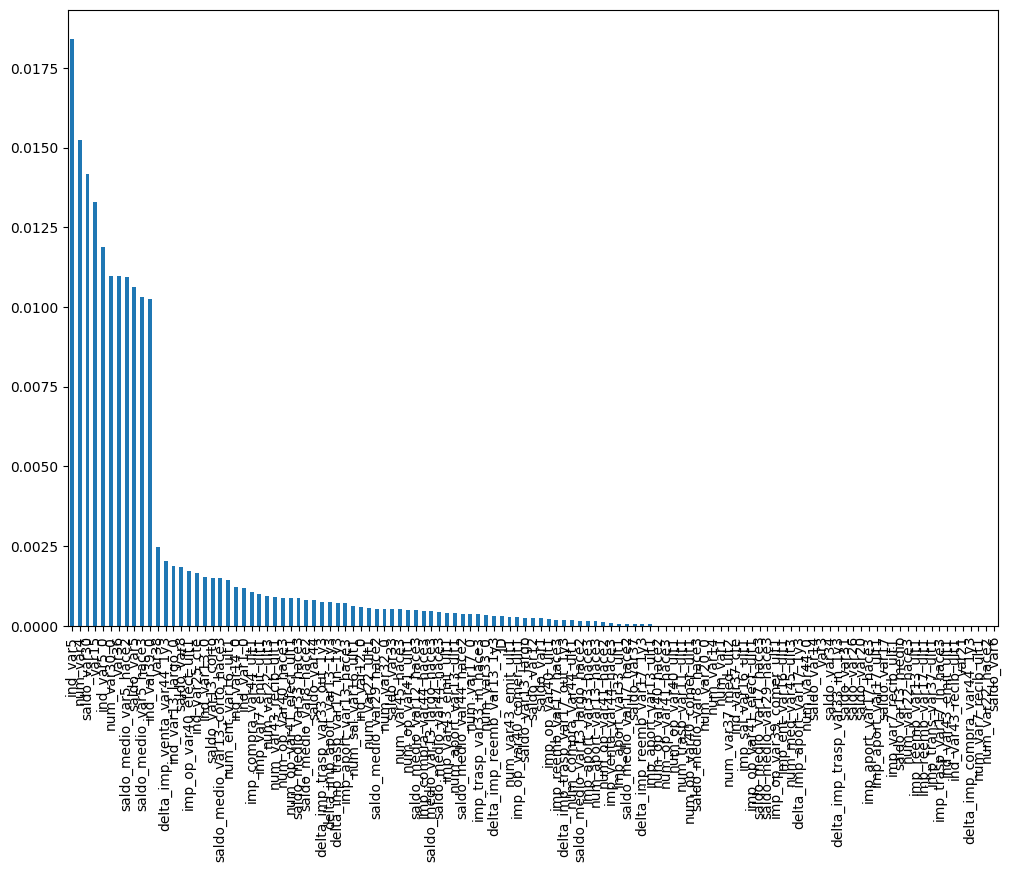

In [44]:
mi.sort_values(ascending=False).plot.bar(figsize=(12,8))

In [45]:
# selecting the top 10 features
sel_ = SelectKBest(mutual_info_classif, k=10).fit(X_train, y_train)
X_train.columns[sel_.get_support()]

Index(['var15', 'ind_var5_0', 'ind_var5', 'ind_var39_0', 'num_var4',
       'num_var30_0', 'saldo_var30', 'var36', 'saldo_medio_var5_hace2',
       'saldo_medio_var5_hace3'],
      dtype='object')

# Dimensionality Reduction
## 1. Missing Value Ratio

In [ ]:
# read the data
train=pd.read_csv("/content/train.csv")

In [48]:
# checking the percentage of missing values in each variable
train.isnull().sum()/len(train)*100

Item_Identifier               0.000000
Item_Weight                  17.165317
Item_Fat_Content              0.000000
Item_Visibility               0.000000
Item_Type                     0.000000
Item_MRP                      0.000000
Outlet_Identifier             0.000000
Outlet_Establishment_Year     0.000000
Outlet_Size                  28.276428
Outlet_Location_Type          0.000000
Outlet_Type                   0.000000
Item_Outlet_Sales             0.000000
dtype: float64

In [49]:
# saving missing values in a variable
a = train.isnull().sum()/len(train)*100
# saving column names in a variable
variables = train.columns
variable = [ ]
for i in range(0,12):
    if a[i]<=20:   #setting the threshold as 20%
        variable.append(variables[i])

The variable to be used are stored in "variable", which contain only those features where the missing values are less than 20%

## 2. Low Variance Filter

we need to calculate the variance of each variable we are given. Then drop the variables having low variance as compared to other variables in our dataset. The reason for doing this, is that variables with a low variance will not affect the target variable.

In [50]:
train['Item_Weight'].fillna(train['Item_Weight'].median(), inplace=True)
train['Outlet_Size'].fillna(train['Outlet_Size'].mode()[0], inplace=True)

In [51]:
#checking whether all the missing values have been filled
train.isnull().sum()/len(train)*100

Item_Identifier              0.0
Item_Weight                  0.0
Item_Fat_Content             0.0
Item_Visibility              0.0
Item_Type                    0.0
Item_MRP                     0.0
Outlet_Identifier            0.0
Outlet_Establishment_Year    0.0
Outlet_Size                  0.0
Outlet_Location_Type         0.0
Outlet_Type                  0.0
Item_Outlet_Sales            0.0
dtype: float64

In [52]:
#calculating the variance for all the numerical variables
train.var()

<ipython-input-52-8be6773484c0>:2: FutureWarning: The default value of numeric_only in DataFrame.var is deprecated. In a future version, it will default to False. In addition, specifying 'numeric_only=None' is deprecated. Select only valid columns or specify the value of numeric_only to silence this warning.
  train.var()


Item_Weight                  1.786956e+01
Item_Visibility              2.662335e-03
Item_MRP                     3.878184e+03
Outlet_Establishment_Year    7.008637e+01
Item_Outlet_Sales            2.912141e+06
dtype: float64

In [56]:
numeric = train[['Item_Weight', 'Item_Visibility', 'Item_MRP', 'Outlet_Establishment_Year']]
var = numeric.var()
numeric = numeric.columns
variable = [ ]
for i in range(0,len(var)):
    if var[i]>=10:   #setting the threshold as 10%
       variable.append(numeric[i])

In [57]:
variable

['Item_Weight', 'Item_MRP', 'Outlet_Establishment_Year']

## 3. High Correlation Filter

High correlation between two variables means they have similar trends and are likely to carry similar information. This can bring down the performance of some models drastically.  We can calculate the correlation between independent numerical variables that are numerical in nature. If the correlation coefficient crosses a certain threshold value, we can drop one of the variables.


As a general guideline, we should keep those variables which show a decent or high correlation with the target variable.

In [58]:
#dropping the target variable and then checking the correlation
df=train.drop('Item_Outlet_Sales', 1)
df.corr()

<ipython-input-58-57ec881481eb>:2: FutureWarning: In a future version of pandas all arguments of DataFrame.drop except for the argument 'labels' will be keyword-only.
  df=train.drop('Item_Outlet_Sales', 1)
<ipython-input-58-57ec881481eb>:3: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  df.corr()


,Item_Weight,Item_Visibility,Item_MRP,Outlet_Establishment_Year
Item_Weight,1.000000,-0.014168,0.024951,0.007739
Item_Visibility,-0.014168,1.000000,-0.001315,-0.074834
Item_MRP,0.024951,-0.001315,1.000000,0.005020
Outlet_Establishment_Year,0.007739,-0.074834,0.005020,1.000000


We don't have any variables with high correlation in our dataset. Generally, if the correlation between a pair of variabels is greater than 0.5-0.6, we should consider dropping one of these variables.

# **Lab Assignment**

Use randomforest classifier on the "diabetes.csv" dataset using one of the filtering techniques mentioned above. 